In [1]:
# @title Cell 1: Environment Setup & Imports
import itertools
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.statespace.sarimax import SARIMAX

drive.mount('/content/drive')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)

Mounted at /content/drive


In [2]:
# @title Cell 2: Data Loading & Preprocessing
DATA_PATH = '/content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 1/Data Pipeline/data/processed/crude_weekly_full.parquet'

df = pd.read_parquet(DATA_PATH)

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df.set_index('date', inplace=True)
df = df.sort_index()

# Drop the trailing row with an unknown future target (same fix as every
# other notebook in this project).
last_valid_idx = df['target_next_week_change'].last_valid_index()
df = df.loc[:last_valid_idx]

# stocks_change, implied_change, stocks_vs_5yr_avg, week_sin, week_cos,
# and is_event already exist in this file -- nothing to rebuild.
# Only genuinely new columns:
df['implied_change_lag1'] = df['implied_change'].shift(1)     # 1-week lag of the strongest feature
df['refinery_util_diff'] = df['refinery_utilisation'].diff()  # rate of change instead of raw level

df = df.dropna(subset=['implied_change_lag1', 'refinery_util_diff',
                        'stocks_vs_5yr_avg', 'target_next_week_change'])
# NOTE: stocks_vs_5yr_avg needs 5 years of history to compute, so it's NaN
# for roughly the first 260 weeks (until ~1996). Those NaNs were the actual
# cause of "SVD did not converge" in Cell 3 -- not a scaling issue.

print(f"Data shape after feature engineering: {df.shape}")
print(f"Range: {df.index.min().date()} to {df.index.max().date()}")

Data shape after feature engineering: (1603, 24)
Range: 1995-12-29 to 2026-09-11


In [3]:
# @title Cell 3: Feature Selection & Multicollinearity Check (VIF)
EXOG_COLS = [
    'implied_change',
    'implied_change_lag1',
    'stocks_change',        # this week's own change -- the natural momentum term
    'refinery_util_diff',   # kept the diff, dropped the raw level (was insignificant)
    'stocks_vs_5yr_avg',
    'is_event',
    'week_sin',
    'week_cos',
]

TARGET_COL = 'target_next_week_change'  # FIXED: was 'stocks_change'

# FIXED: standardize before computing VIF. The raw columns span ~6 orders of
# magnitude (stocks_vs_5yr_avg reaches ~146,000; week_sin/week_cos are -1 to
# 1; is_event is 0/1), which makes the underlying matrix decomposition
# numerically unstable -> "LinAlgError: SVD did not converge". VIF is
# scale-invariant in theory, so standardizing first doesn't change what's
# being measured, it just makes the computation solvable.
from sklearn.preprocessing import StandardScaler

X_scaled = pd.DataFrame(
    StandardScaler().fit_transform(df[EXOG_COLS]),
    columns=EXOG_COLS, index=df.index
)
X_vif = X_scaled.assign(intercept=1)
vif_df = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).sort_values(by='VIF', ascending=False)

print("--- Variance Inflation Factor (VIF) Summary ---")
print(vif_df[vif_df['Feature'] != 'intercept'].to_string(index=False))
print("\nRule of thumb: VIF > 5-10 signals real redundancy worth addressing.")



--- Variance Inflation Factor (VIF) Summary ---
            Feature      VIF
     implied_change 2.400750
      stocks_change 2.221355
implied_change_lag1 1.228375
  stocks_vs_5yr_avg 1.073359
           week_cos 1.068869
 refinery_util_diff 1.062481
           week_sin 1.058954
           is_event 1.019889

Rule of thumb: VIF > 5-10 signals real redundancy worth addressing.


In [4]:
# @title Cell 4: Train ,Test  and Split
TEST_SIZE = 104  # FIXED: 52 -> 104, matches the 2-year holdout used elsewhere

train_df = df.iloc[:-TEST_SIZE]
test_df = df.iloc[-TEST_SIZE:]

y_train = train_df[TARGET_COL]
X_train = train_df[EXOG_COLS]
y_test = test_df[TARGET_COL]
X_test = test_df[EXOG_COLS]

print(f"Train set: {train_df.index.min().date()} to {train_df.index.max().date()} ({len(train_df)} rows)")
print(f"Test set:  {test_df.index.min().date()} to {test_df.index.max().date()} ({len(test_df)} rows)")

Train set: 1995-12-29 to 2024-09-13 (1499 rows)
Test set:  2024-09-20 to 2026-09-11 (104 rows)


In [5]:
# @title Cell 5: SARIMAX Model Training & Diagnostic Summary
order = (2, 0, 2)              # matches the AIC grid-search winner from Task 4.2
seasonal_order = (0, 0, 0, 0)  # FIXED: dropped (1,0,1,52) -- week_sin/cos already cover seasonality

model = SARIMAX(
    endog=y_train,
    exog=X_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False,
    initialization='approximate_diffuse',  # FIXED: avoids solving the Lyapunov
                                            # equation for the starting state,
                                            # which is what "SVD did not
                                            # converge" usually comes from here
)
results = model.fit(disp=False, maxiter=200)
print(results.summary())



/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)


                                  SARIMAX Results                                  
Dep. Variable:     target_next_week_change   No. Observations:                 1499
Model:                    SARIMAX(2, 0, 2)   Log Likelihood              -14598.761
Date:                     Tue, 29 Sep 2026   AIC                          29223.521
Time:                             01:48:49   BIC                          29292.585
Sample:                         12-29-1995   HQIC                         29249.251
                              - 09-13-2024                                         
Covariance Type:                       opg                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
implied_change          0.0726      0.028      2.605      0.009       0.018       0.127
implied_change_lag1     0.0347      0.029      1.191      0.234 

--- Out-of-Sample Performance (genuine one-week-ahead forecast) ---
MAE:  3711.2078
RMSE: 4770.7254
R²:   0.0509


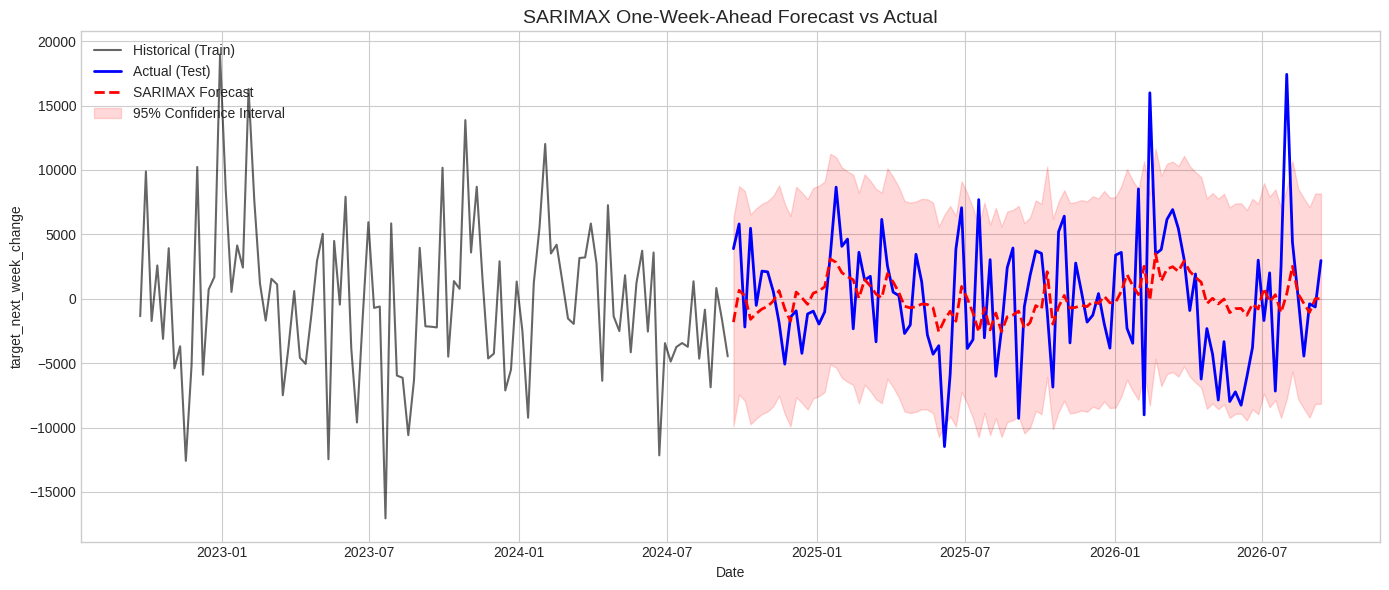

In [6]:
# @title Cell 6: Forecasting & Model Evaluation
predictions = results.get_forecast(steps=len(test_df), exog=X_test)
pred_mean = predictions.predicted_mean
pred_ci = predictions.conf_int()

mae = mean_absolute_error(y_test, pred_mean)
rmse = np.sqrt(mean_squared_error(y_test, pred_mean))
r2 = r2_score(y_test, pred_mean)

print("--- Out-of-Sample Performance (genuine one-week-ahead forecast) ---")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

plt.figure(figsize=(14, 6))
plt.plot(train_df.index[-104:], y_train.tail(104), label='Historical (Train)', color='black', alpha=0.6)
plt.plot(test_df.index, y_test, label='Actual (Test)', color='blue', linewidth=2)
plt.plot(test_df.index, pred_mean, label='SARIMAX Forecast', color='red', linestyle='--', linewidth=2)
plt.fill_between(test_df.index, pred_ci.iloc[:, 0], pred_ci.iloc[:, 1], color='red', alpha=0.15, label='95% Confidence Interval')
plt.title('SARIMAX One-Week-Ahead Forecast vs Actual', fontsize=14)
plt.xlabel('Date')
plt.ylabel(TARGET_COL)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [7]:
output_dir = '/content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 2/4. Model Training and Optimization/4.2 SARIMAX statistical model'
os.makedirs(output_dir, exist_ok=True)
pd.DataFrame([{'Model': f'SARIMAX{order}+VIF-pruned', 'MAE (kb)': round(mae, 2),
               'RMSE (kb)': round(rmse, 2), 'R² Score': round(r2, 4)}]).to_csv(
    os.path.join(output_dir, 'sarimax_vif_metrics.csv'), index=False)
print(f"Saved metrics to: {output_dir}")

Saved metrics to: /content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 2/4. Model Training and Optimization/4.2 SARIMAX statistical model


In [9]:
import joblib
import json
import os

# 1. Output directory for SARIMAX
SARIMAX_DIR = '/content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 2/4. Model Training and Optimization/4.2 SARIMAX model'
os.makedirs(SARIMAX_DIR, exist_ok=True)

# 2. Save Fitted SARIMAX Model Results Object ('results')
joblib.dump(results, os.path.join(SARIMAX_DIR, 'sarimax_model.pkl'))

# 3. Save Target Scaling Parameters (y_mean, y_std) for Gezlan
scaling_stats = {
    'y_mean': float(y_mean) if 'y_mean' in globals() else float(y_train.mean()),
    'y_std': float(y_std) if 'y_std' in globals() else float(y_train.std())
}

with open(os.path.join(SARIMAX_DIR, 'scaling_stats.json'), 'w') as f:
    json.dump(scaling_stats, f)

print(f"Successfully saved sarimax_model.pkl and scaling_stats.json to:\n{SARIMAX_DIR}")

Successfully saved sarimax_model.pkl and scaling_stats.json to:
/content/drive/MyDrive/Tech Fem team - SIC capstone project/Week 2/4. Model Training and Optimization/4.2 SARIMAX model
